# Fig. S2 — Effect of individual payoff parameters, and the regime map
A, B: one payoff entry varied over $[-1, 1]$ with the other three set to zero; final $N(T)$ and $x(T)$ at $T=30$ days
($N(0)=10^5$, $x(0)=0.5$, $K=10^{10}$). C: game classification in the (β, γ) plane for α = 0.4, δ = 0.6.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lf_model import *
set_style()
from matplotlib.patches import Rectangle

In [2]:
p = np.linspace(-1, 1, 401)
z = np.zeros_like(p)
sweeps = {"alpha": (p, z, z, z), "beta": (z, p, z, z), "gamma": (z, z, p, z), "delta": (z, z, z, p)}
final = {name: simulate(*args, x0=0.5, T=30.0, dt=0.01) for name, args in sweeps.items()}
style = {"alpha": ("#1b9e77", ":"), "beta": ("#d95f02", "-"), "gamma": ("#7570b3", "-."), "delta": ("#e7298a", "--")}
label = {"alpha": r"$\alpha$", "beta": r"$\beta$", "gamma": r"$\gamma$", "delta": r"$\delta$"}

Saved ../figures/FigS2_parameter_sweeps_regime_map.png/.pdf


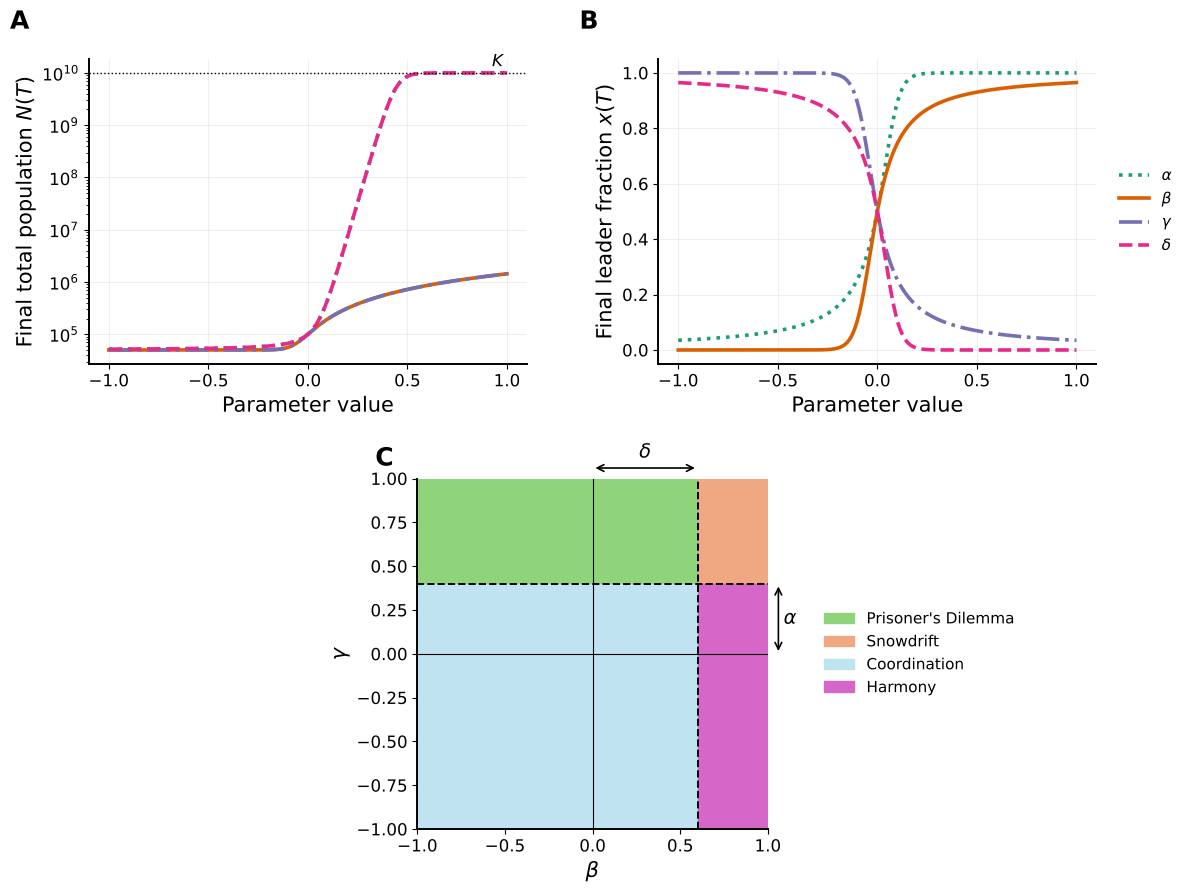

In [3]:
fig = plt.figure(figsize=(13, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.35, wspace=0.3)
axA, axB = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
for name in TARGETS:
    c, ls = style[name]
    axA.plot(p, final[name][1], color=c, ls=ls, lw=2.6, label=label[name])
    axB.plot(p, final[name][0], color=c, ls=ls, lw=2.6, label=label[name])
axA.set_yscale("log"); axA.axhline(K, color="k", ls=":", lw=1); axA.text(0.98, K * 1.3, "$K$", ha="right")
axA.set_ylabel("Final total population $N(T)$"); axB.set_ylabel("Final leader fraction $x(T)$")
for ax, letter in [(axA, "A"), (axB, "B")]:
    ax.set_xlabel("Parameter value"); ax.grid(alpha=0.2); panel_letter(ax, letter)
axB.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

axC = fig.add_subplot(gs[1, :]); L = 1.0
regions = [("Prisoner's Dilemma", -L, ALPHA, DELTA + L, L - ALPHA, "#8fd47a"),
           ("Snowdrift", DELTA, ALPHA, L - DELTA, L - ALPHA, "#f0a882"),
           ("Coordination", -L, -L, DELTA + L, ALPHA + L, "#bfe3f0"),
           ("Harmony", DELTA, -L, L - DELTA, ALPHA + L, "#d667c9")]
for name, x0_, y0_, w, h, c in regions:
    axC.add_patch(Rectangle((x0_, y0_), w, h, color=c, label=name))
axC.axvline(DELTA, color="k", ls="--", lw=1.4); axC.axhline(ALPHA, color="k", ls="--", lw=1.4)
axC.axvline(0, color="k", lw=0.8); axC.axhline(0, color="k", lw=0.8)
axC.annotate("", xy=(DELTA, 1.06), xytext=(0, 1.06), arrowprops=dict(arrowstyle="<->", lw=1.2), annotation_clip=False)
axC.text(DELTA / 2, 1.09, r"$\delta$", ha="center", va="bottom", fontsize=14)
axC.annotate("", xy=(1.06, ALPHA), xytext=(1.06, 0), arrowprops=dict(arrowstyle="<->", lw=1.2), annotation_clip=False)
axC.text(1.09, ALPHA / 2, r"$\alpha$", ha="left", va="center", fontsize=14)
axC.set_xlim(-L, L); axC.set_ylim(-L, L); axC.set_aspect("equal")
axC.set_xlabel(r"$\beta$"); axC.set_ylabel(r"$\gamma$")
axC.legend(loc="center left", bbox_to_anchor=(1.12, 0.5), frameon=False)
panel_letter(axC, "C", x=-0.12, y=1.02)
save(fig, "FigS2_parameter_sweeps_regime_map")
plt.show()